# Week 7a: A neural network from scratch (NumPy only)

You'll build a 2-layer network by hand, the same job as your Week 2 categorizer (description → category), and **prove your backpropagation is right** with a gradient check. No PyTorch yet: every number is yours.

Network: TF-IDF features → **64 hidden ReLU units** → **11 outputs** (softmax).

Spec: `docs/superpowers/specs/2026-10-23-deep-learning-design.md`

## Setup (given)
Your Week 2 data, cleaning, split and TF-IDF, turned into plain NumPy arrays. `Y_train` is one-hot: one column per category, a 1 in the right one.

In [1]:
import sys

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.model_selection import train_test_split

sys.path.insert(0, '../service')
from clean import clean_description   # the same cleaning the deployed model uses

df = pd.read_csv('../data/fake_transactions.csv')
df['Clean'] = df['Description'].fillna('').str.strip().apply(clean_description)
data = df[df['Clean'] != '']
text_train, text_test, cat_train, cat_test = train_test_split(
    data['Clean'], data['Category'], test_size=0.2, stratify=data['Category'], random_state=42)

vec = TfidfVectorizer(analyzer='char_wb', ngram_range=(2, 4)).fit(text_train)
X_train, X_test = vec.transform(text_train).toarray(), vec.transform(text_test).toarray()   # float64
LABELS = sorted(data['Category'].unique())
y_train = np.array([LABELS.index(c) for c in cat_train])
y_test = np.array([LABELS.index(c) for c in cat_test])
Y_train = np.eye(len(LABELS))[y_train]

N_IN, N_HIDDEN, N_OUT = X_train.shape[1], 64, len(LABELS)
print(X_train.shape, X_test.shape, N_OUT, 'categories')

(1102, 1337) (276, 1337) 11 categories


---
## A. Neurons, layers and activations
A layer is `X @ W + b`: every output is a weighted sum of the inputs plus a bias.

Write two functions:
- `relu(z)`: `max(0, z)` element-wise
- `softmax(z)`: for each row, `exp(z) / sum(exp(z))`, so the row adds up to 1. Subtract the row's max first (`z - z.max(axis=1, keepdims=True)`): the result is the same, but `exp` can't overflow.

**Think:** why do we need ReLU at all? What would two layers `(X @ W1) @ W2` be without it? (Hint: multiply `W1 @ W2` first.)

In [2]:
# TODO
def relu(z):
    """max(0, z) element-wise."""
    return np.maximum(0, z)

def softmax(z):
    """Row-wise softmax; subtracting the row max keeps exp() from overflowing."""
    z = z - z.max(axis=1, keepdims=True)
    e = np.exp(z)
    return e / e.sum(axis=1, keepdims=True)

# Checks
assert (relu(np.array([-2.0, 0.0, 3.0])) == [0, 0, 3]).all()
p = softmax(np.array([[1.0, 2.0, 3.0], [1000.0, 1001.0, 1002.0]]))
assert np.allclose(p.sum(axis=1), 1)
assert np.allclose(p[0], p[1])           # shift-invariant, and no overflow at 1000
print(p.round(3))

[[0.09  0.245 0.665]
 [0.09  0.245 0.665]]


---
## B. Loss
`cross_entropy(probs, Y)` = the mean over rows of `−Σ Y · log(probs)`. Add `1e-12` inside the log so it never sees 0.

**Think:** we report accuracy, but we **train** on cross-entropy. Why can't gradient descent use accuracy directly? (Hint: what happens to accuracy when a weight changes by a tiny amount?)

In [3]:
# TODO
def cross_entropy(probs, Y):
    """Mean over rows of -sum(Y * log(probs)); 1e-12 keeps log away from 0."""
    return float(-(Y * np.log(probs + 1e-12)).sum(axis=1).mean())

# Checks
Y = np.eye(3)[[0, 2]]
perfect = np.array([[1.0, 0, 0], [0, 0, 1.0]])
uniform = np.full((2, 3), 1 / 3)
assert cross_entropy(perfect, Y) < 1e-9                    # confident and right → ~0
assert np.isclose(cross_entropy(uniform, Y), np.log(3))    # pure guessing → log(K)
print(f'guessing among {N_OUT} classes: loss ≈ {np.log(N_OUT):.2f}')

guessing among 11 classes: loss ≈ 2.40


---
## C. Forward pass
- `init_params()`: a dict with `W1 (N_IN×N_HIDDEN)`, `b1`, `W2 (N_HIDDEN×N_OUT)`, `b2`. Use `rng = np.random.default_rng(0)`, weights `rng.standard_normal(shape) * np.sqrt(2 / fan_in)` (draw `W1` first, then `W2`), biases zeros. Notebook 08 rebuilds exactly these weights, so keep this order.
- `forward(params, X)`: `Z1 = X @ W1 + b1`, `A1 = relu(Z1)`, `Z2 = A1 @ W2 + b2`, `probs = softmax(Z2)`. Return `probs` and a `cache` dict with `X, Z1, A1, probs` (backprop needs them).

Before training, the loss should be close to `log(11) ≈ 2.4`. Why?

In [4]:
# TODO
def init_params():
    """He initialisation: weights ~ N(0, 2/fan_in), biases 0. W1 is drawn before W2."""
    rng = np.random.default_rng(0)
    return {
        'W1': rng.standard_normal((N_IN, N_HIDDEN)) * np.sqrt(2 / N_IN),
        'b1': np.zeros(N_HIDDEN),
        'W2': rng.standard_normal((N_HIDDEN, N_OUT)) * np.sqrt(2 / N_HIDDEN),
        'b2': np.zeros(N_OUT),
    }

def forward(params, X):
    Z1 = X @ params['W1'] + params['b1']
    A1 = relu(Z1)
    Z2 = A1 @ params['W2'] + params['b2']
    probs = softmax(Z2)
    cache = {'X': X, 'Z1': Z1, 'A1': A1, 'probs': probs}
    return probs, cache

# Checks
params = init_params()
probs, cache = forward(params, X_train)
assert probs.shape == (len(X_train), N_OUT) and np.allclose(probs.sum(axis=1), 1)
loss0 = cross_entropy(probs, Y_train)
print(f'untrained loss {loss0:.3f}  vs  log(11) = {np.log(N_OUT):.3f}')

untrained loss 2.421  vs  log(11) = 2.398


---
## D. Backpropagation by hand
`backward(params, cache, Y)` returns a dict of gradients with the **same keys and shapes** as `params`.

Work backwards with the chain rule. The first step is given, because softmax + cross-entropy simplify beautifully:

`dZ2 = (probs − Y) / n`  (n = rows in the batch)

Then:
- `dW2`: how does the loss change with `W2`? (`Z2 = A1 @ W2`, so it involves `A1.T`)
- `db2`: sum `dZ2` over rows
- `dA1`: pass the gradient back through `W2`
- `dZ1`: ReLU lets the gradient through only where `Z1 > 0`
- `dW1`, `db1`: the same pattern as layer 2

**Tip:** check every shape. `dW2` must be `(64, 11)` like `W2`.

In [5]:
# TODO
def backward(params, cache, Y):
    X, Z1, A1, probs = cache['X'], cache['Z1'], cache['A1'], cache['probs']
    n = X.shape[0]

    dZ2 = (probs - Y) / n                    # (n, 11)   softmax + cross-entropy
    dW2 = A1.T @ dZ2                         # (64, 11)
    db2 = dZ2.sum(axis=0)                    # (11,)

    dA1 = dZ2 @ params['W2'].T               # (n, 64)
    dZ1 = dA1 * (Z1 > 0)                     # (n, 64)   ReLU gate
    dW1 = X.T @ dZ1                          # (1337, 64)
    db1 = dZ1.sum(axis=0)                    # (64,)

    return {'W1': dW1, 'b1': db1, 'W2': dW2, 'b2': db2}

# Check: every gradient has the shape of its parameter
grads = backward(params, cache, Y_train)
for k in params:
    assert grads[k].shape == params[k].shape, (k, grads[k].shape, params[k].shape)
    print(f'{k}: {grads[k].shape}')

W1: (1337, 64)
b1: (64,)
W2: (64, 11)
b2: (11,)


---
## E. Gradient check (given)
The proof your maths is right. For a few weights, nudge the weight by ±ε, measure the loss, and compare `(L(w+ε) − L(w−ε)) / 2ε` with your gradient. If the relative error is below 1e-6, your backprop is correct.

In [6]:
def gradient_check(params, X, Y, eps=1e-5, per_param=20, seed=1):
    rng = np.random.default_rng(seed)
    grads = backward(params, forward(params, X)[1], Y)
    worst = 0.0
    for name, P in params.items():
        G = grads[name]
        assert G.shape == P.shape, f'{name}: gradient shape {G.shape} vs {P.shape}'
        assert np.abs(G).max() > 1e-8, f'{name}: gradient is all ~0'
        # weights whose gradient is too tiny to measure numerically (e.g. unused inputs) can't be checked
        candidates = np.argwhere(np.abs(G) > 1e-6)
        for idx in map(tuple, candidates[rng.choice(len(candidates), min(per_param, len(candidates)), replace=False)]):
            old = P[idx]
            P[idx] = old + eps; plus = cross_entropy(forward(params, X)[0], Y)
            P[idx] = old - eps; minus = cross_entropy(forward(params, X)[0], Y)
            P[idx] = old
            numeric = (plus - minus) / (2 * eps)
            worst = max(worst, abs(G[idx] - numeric) / max(abs(G[idx]) + abs(numeric), 1e-12))
    return worst

worst = gradient_check(init_params(), X_train[:32], Y_train[:32])
print(f'worst relative error: {worst:.2e}')
assert worst < 1e-6, 'backprop has a bug: compare each gradient with its numeric value'
print('backprop ✓')

worst relative error: 1.35e-07
backprop ✓


---
## F. Train it
Mini-batch **SGD**: shuffle the rows each epoch, then for each batch of 64: forward, backward, and `param -= LR * grad` for every parameter.

Start with `LR = 0.5`, 30 epochs. After each epoch record the training loss, train accuracy and test accuracy in a list of dicts, then `history = pd.DataFrame(...).set_index('epoch')`. The `accuracy` helper is given.

In [11]:
def accuracy(params, X, y):
    return float((forward(params, X)[0].argmax(axis=1) == y).mean())

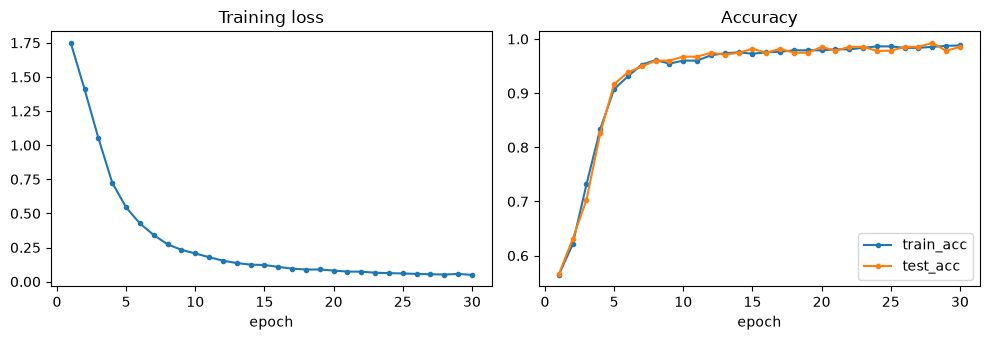

,loss,train_acc,test_acc
epoch,,,
1,1.749,0.564,0.565
5,0.544,0.907,0.917
10,0.206,0.960,0.967
20,0.081,0.979,0.986
30,0.049,0.988,0.986


In [9]:
# TODO
LR, EPOCHS, BATCH = 0.5, 30, 64

params = init_params()                      # fresh weights, same as the gradient check
shuffle_rng = np.random.default_rng(1)      # separate RNG, so init stays reproducible
n = len(X_train)
rows = []

for epoch in range(1, EPOCHS + 1):
    order = shuffle_rng.permutation(n)
    for start in range(0, n, BATCH):
        idx = order[start:start + BATCH]
        _, cache = forward(params, X_train[idx])
        grads = backward(params, cache, Y_train[idx])
        for k in params:
            params[k] -= LR * grads[k]

    probs, _ = forward(params, X_train)
    rows.append({'epoch': epoch,
                 'loss': cross_entropy(probs, Y_train),
                 'train_acc': accuracy(params, X_train, y_train),
                 'test_acc': accuracy(params, X_test, y_test)})

history = pd.DataFrame(rows).set_index('epoch')

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(10, 3.5))
history['loss'].plot(ax=ax1, title='Training loss', marker='.')
history[['train_acc', 'test_acc']].plot(ax=ax2, title='Accuracy', marker='.')
plt.tight_layout(); plt.show()

history.iloc[[0, 4, 9, 19, 29]].round(3)

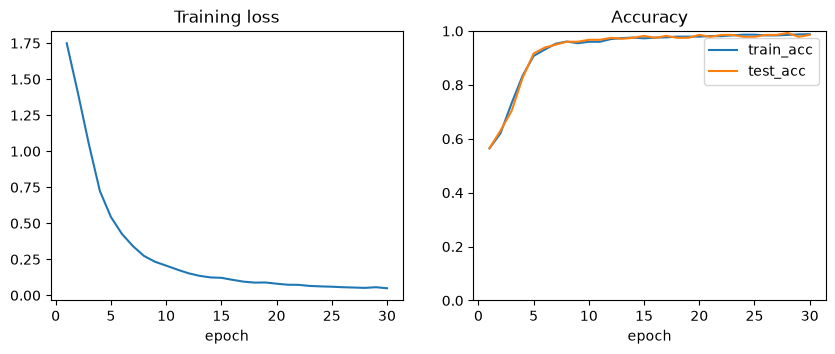

test accuracy: 98.6%  (Week 2 scikit-learn: 96.3%)


In [10]:
# Plot (given)
fig, ax = plt.subplots(1, 2, figsize=(10, 3.5))
history['loss'].plot(ax=ax[0], title='Training loss')
history[['train_acc', 'test_acc']].plot(ax=ax[1], title='Accuracy', ylim=(0, 1))
plt.show()
print(f"test accuracy: {history['test_acc'].iloc[-1]:.1%}  (Week 2 scikit-learn: 96.3%)")

**Think:** re-run training with `LR = 5` and with `LR = 0.05` (keep the rest). What happens to the loss curve in each case, and why?

**Your answer:**
- **LR = 5: too big, it never learns.** The loss starts at 1.95, bounces between about 1.85 and 2.4 with a spike to ~3.1 at epoch 18, and ends at 2.14, higher than where it started and barely better than guessing (log 11 ≈ 2.40). Test accuracy is only 31.2%. Each step is 10× larger than at 0.5, so every update jumps past the low point of the loss and lands on the other side, often higher; the weights keep overshooting instead of settling.
- **LR = 0.05: too small, it learns slowly.** The loss falls smoothly and steadily, from 2.26 to 0.98, but after 30 epochs it is still 20× higher than at LR = 0.5 (0.049), and test accuracy is 76.1%. The gradient points the right way, but each step is 10× smaller, so 30 epochs only cover part of the way down; with many more epochs it would get there.
- **LR = 0.5 is in between:** steps big enough to reach a loss of 0.049 and 98.6% test accuracy in 30 epochs, but small enough that the loss goes down every epoch without bouncing.

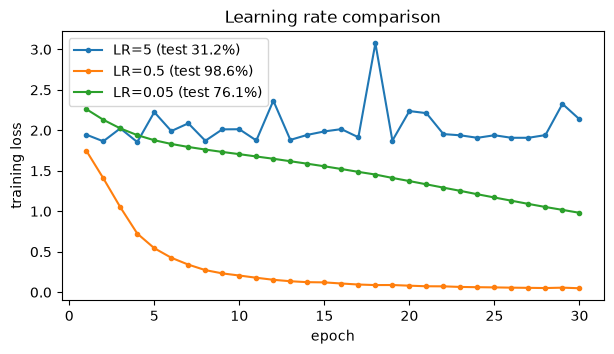

LR=5     first loss 1.947  last loss 2.137  min loss 1.855  test acc 31.2%
LR=0.5   first loss 1.749  last loss 0.049  min loss 0.049  test acc 98.6%
LR=0.05  first loss 2.262  last loss 0.981  min loss 0.981  test acc 76.1%


In [12]:
def train(lr, epochs=30, batch=64):
    p = init_params()
    rng = np.random.default_rng(1)
    losses = []
    for _ in range(epochs):
        order = rng.permutation(len(X_train))
        for s in range(0, len(X_train), batch):
            idx = order[s:s + batch]
            _, c = forward(p, X_train[idx])
            g = backward(p, c, Y_train[idx])
            for k in p:
                p[k] -= lr * g[k]
        losses.append(cross_entropy(forward(p, X_train)[0], Y_train))
    return losses, accuracy(p, X_test, y_test)

results = {lr: train(lr) for lr in [5, 0.5, 0.05]}

fig, ax = plt.subplots(figsize=(7, 3.5))
for lr, (losses, acc) in results.items():
    ax.plot(range(1, 31), losses, marker='.', label=f'LR={lr} (test {acc:.1%})')
ax.set(xlabel='epoch', ylabel='training loss', title='Learning rate comparison')
ax.legend(); plt.show()

for lr, (losses, acc) in results.items():
    print(f'LR={lr:<5} first loss {losses[0]:.3f}  last loss {losses[-1]:.3f}  '
          f'min loss {min(losses):.3f}  test acc {acc:.1%}')